In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv(r"C:\Users\FCT\Downloads\train.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


**Exploring the dataset**

In [3]:
df.shape

(614, 13)

In [4]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [6]:
df.dtypes

Loan_ID               object
Gender                object
Married               object
Dependents            object
Education             object
Self_Employed         object
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area         object
Loan_Status           object
dtype: object

**Checking for duplicates**

In [7]:
df.duplicated().sum()

np.int64(0)

**Dropping duplicate rows**

In [8]:
df.drop_duplicates(inplace=True)

**Missing values check**

In [9]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [10]:
df.isna().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

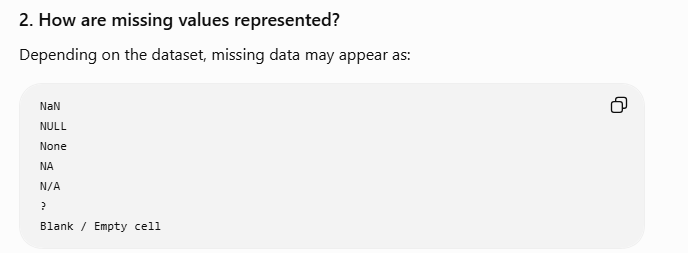

In [11]:
df.isnull().mean() * 100

Loan_ID              0.000000
Gender               2.117264
Married              0.488599
Dependents           2.442997
Education            0.000000
Self_Employed        5.211726
ApplicantIncome      0.000000
CoapplicantIncome    0.000000
LoanAmount           3.583062
Loan_Amount_Term     2.280130
Credit_History       8.143322
Property_Area        0.000000
Loan_Status          0.000000
dtype: float64

In [12]:
# If only a small number of rows have missing values, we can remove those rows.

# df.dropna()

**Seperate out numerical columns & categorical columns**

In [13]:
numerical_cols = df.select_dtypes(include='number').columns
categorical_cols = df.select_dtypes(include='object').columns

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Numerical Columns:
Index(['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History'],
      dtype='object')

Categorical Columns:
Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'Property_Area', 'Loan_Status'],
      dtype='object')


In [14]:
df['LoanAmount'].describe()

count    592.000000
mean     146.412162
std       85.587325
min        9.000000
25%      100.000000
50%      128.000000
75%      168.000000
max      700.000000
Name: LoanAmount, dtype: float64

**Checking outliers for imputation of missing values**

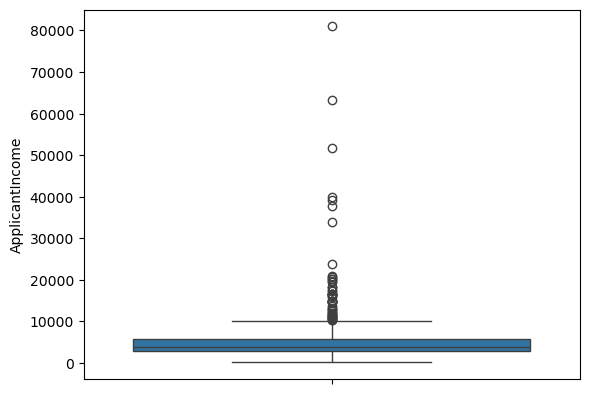

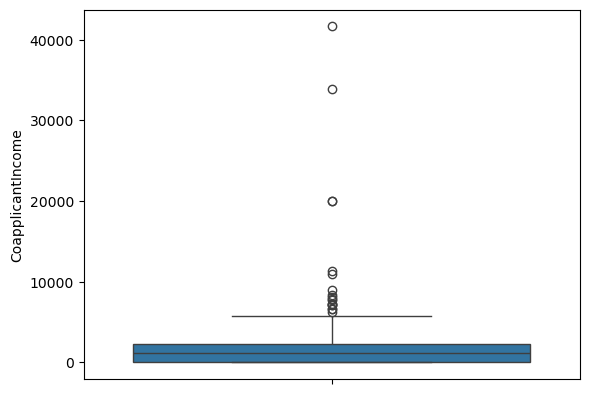

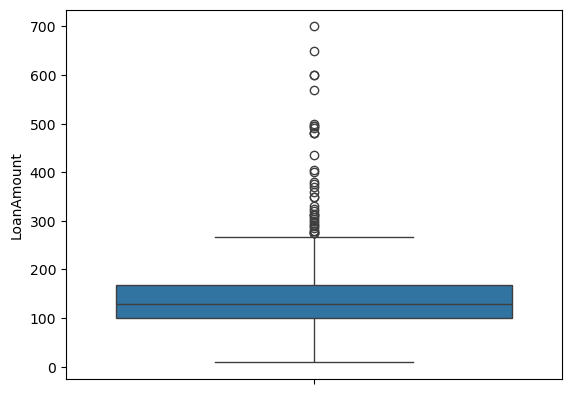

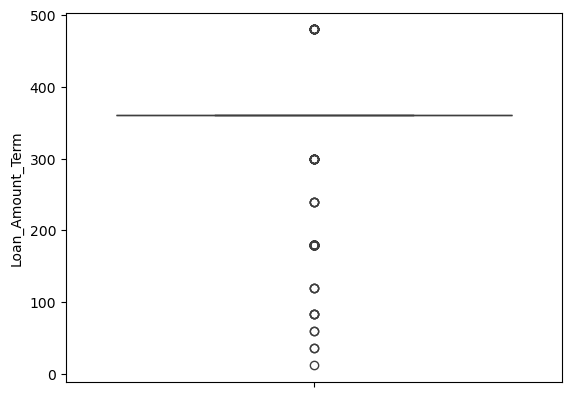

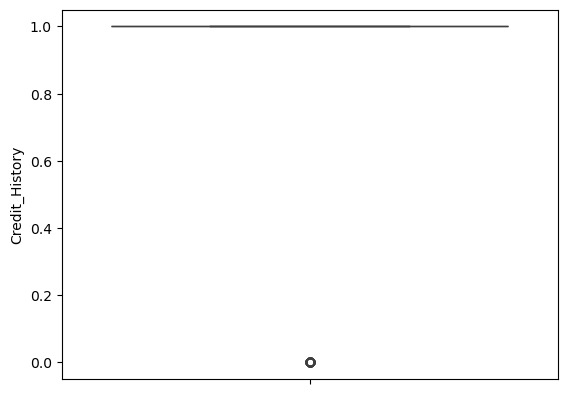

In [15]:
import matplotlib.pyplot as plt
for i in numerical_cols:
    sns.boxplot(df[i].dropna())
    plt.show()

**Here all the three numerical columns contain outliers, so we impute those missing values with median**

In [16]:
num_cols = ['LoanAmount','Loan_Amount_Term', 'Credit_History']
for i in num_cols:
    df[i] = df[i].fillna(df[i].median())

In [17]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64

**Missing value imputation for categorical columns**

In [18]:
cat_cols = ['Gender', 'Dependents', 'Self_Employed', 'Married']

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [19]:
df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

**Handling outliers**

1. What is an outlier?

An outlier is an observation that is unusually far away from most of the other observations.

Example:

Age: 22, 25, 27, 29, 31, 30, 28, 150

150 is likely an outlier.

**First detect outliers using IQR => The most commonly taught method is the IQR method.**

Formula
IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

In [20]:
num_cols = df.select_dtypes(include='number').columns

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    
    print(col, ":", outliers)

ApplicantIncome : 50
CoapplicantIncome : 18
LoanAmount : 41
Loan_Amount_Term : 88
Credit_History : 89


In [21]:
# Cap outliers instead

# For most data-analysis projects, capping is often safer than automatically deleting rows:

num_cols = df.select_dtypes(include='number').columns

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    df[col] = df[col].clip(lower, upper)

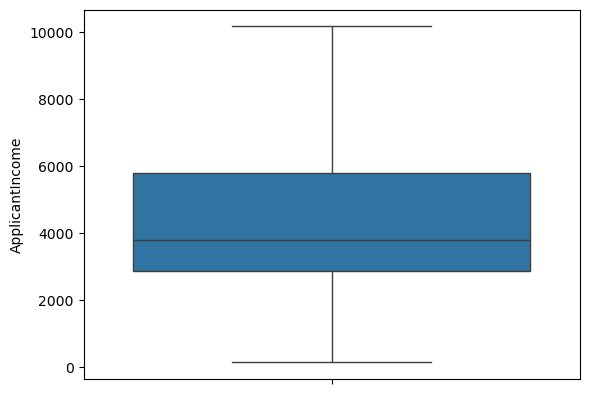

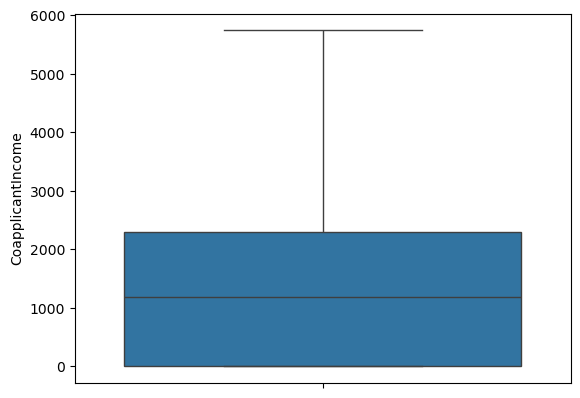

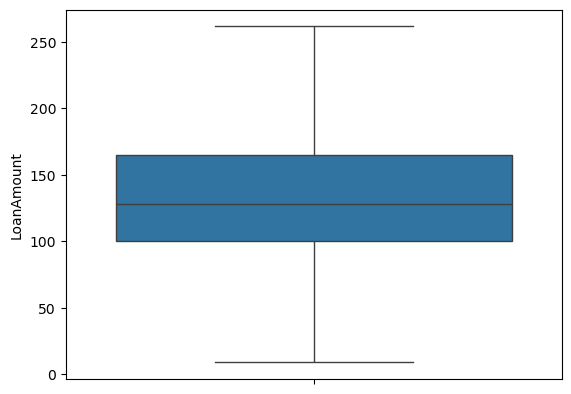

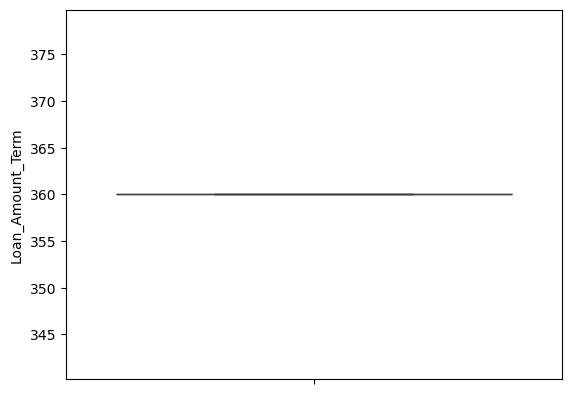

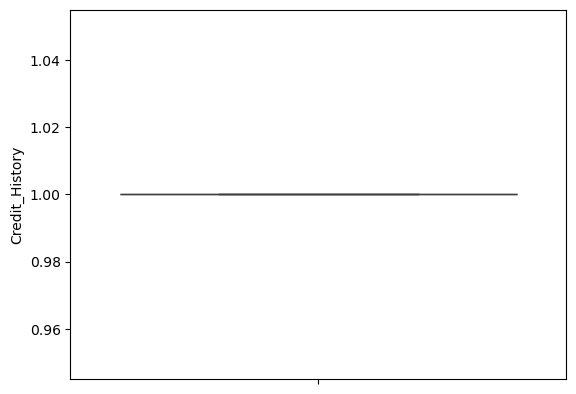

In [22]:
#Now check
import matplotlib.pyplot as plt
for i in numerical_cols:
    sns.boxplot(df[i].dropna())
    plt.show()

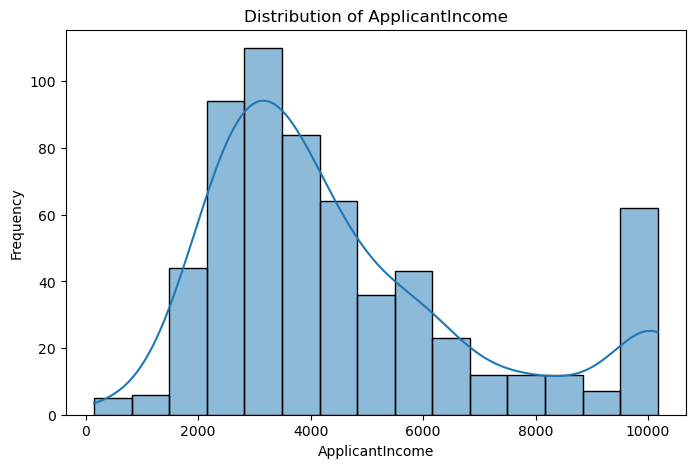

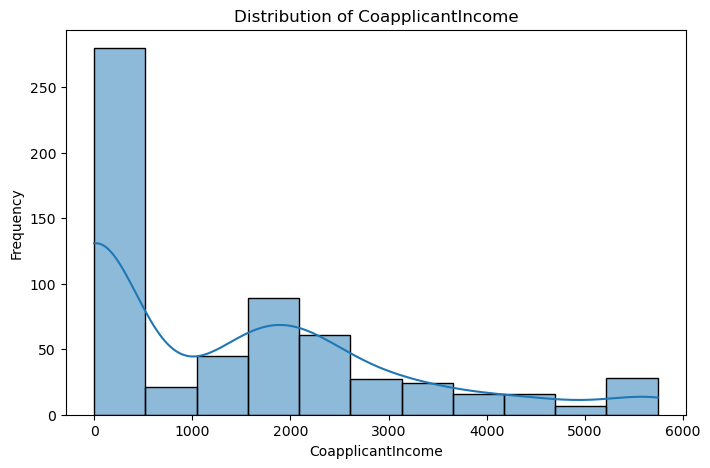

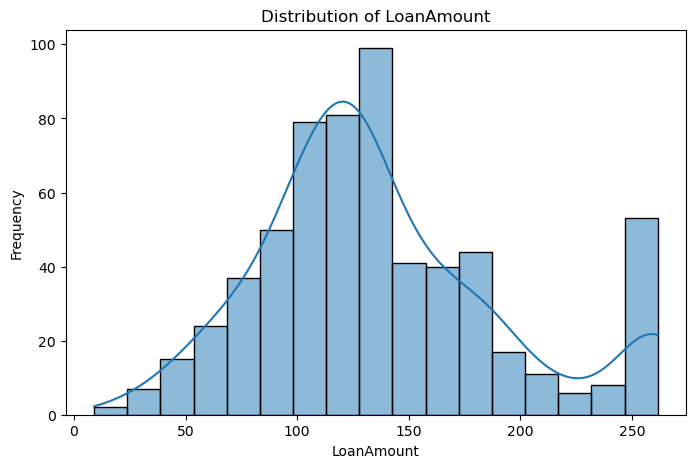

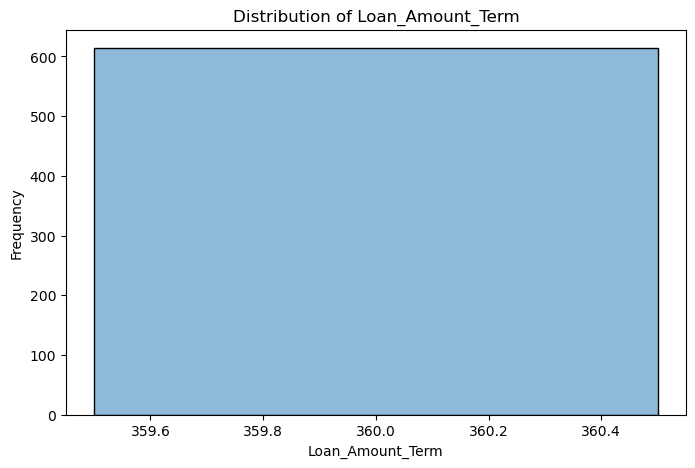

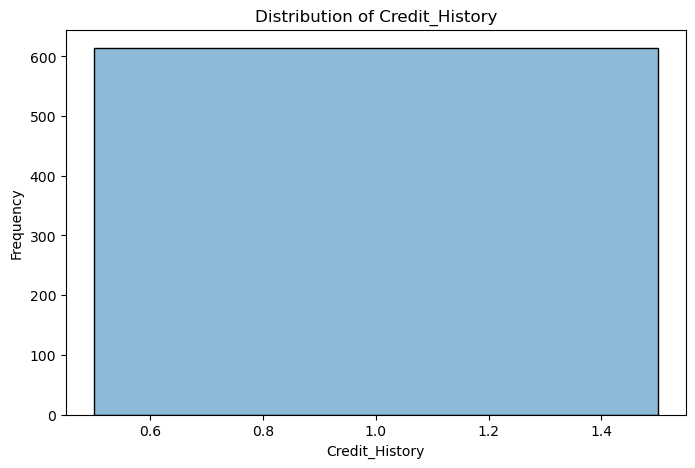

In [23]:
# Histogram + KDE for all numerical columns
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = df.select_dtypes(include='number').columns

for col in num_cols:
    plt.figure(figsize=(8, 5))
    
    sns.histplot(df[col], kde=True)
    
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    
    plt.show()

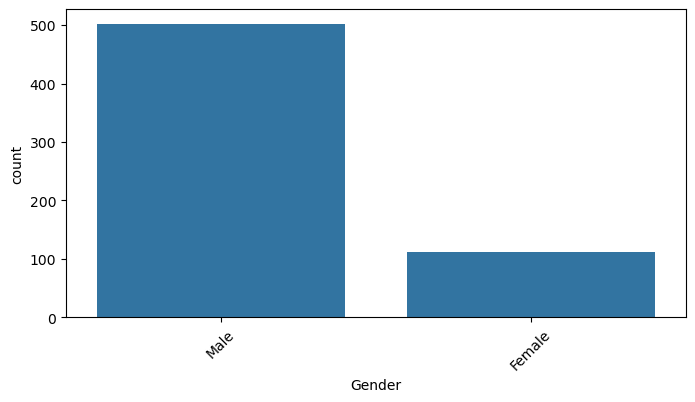

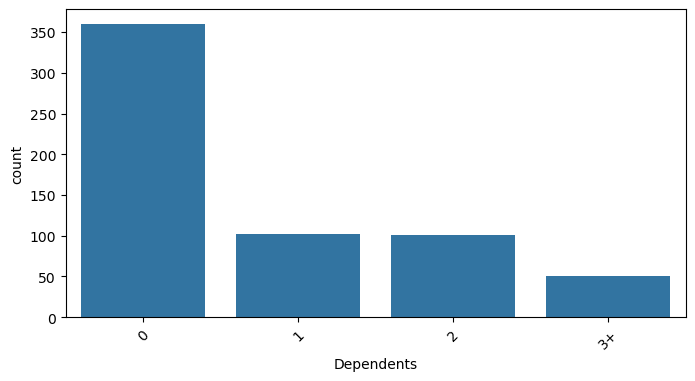

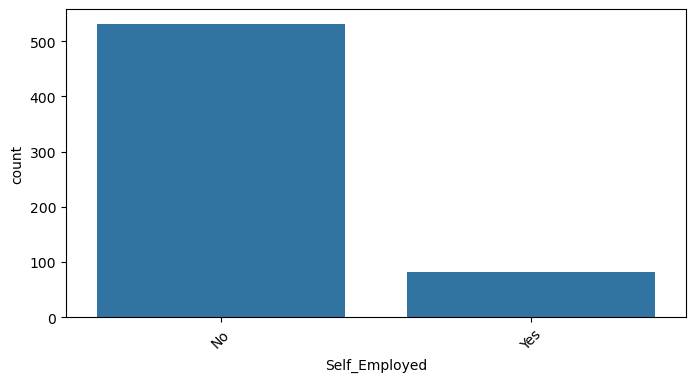

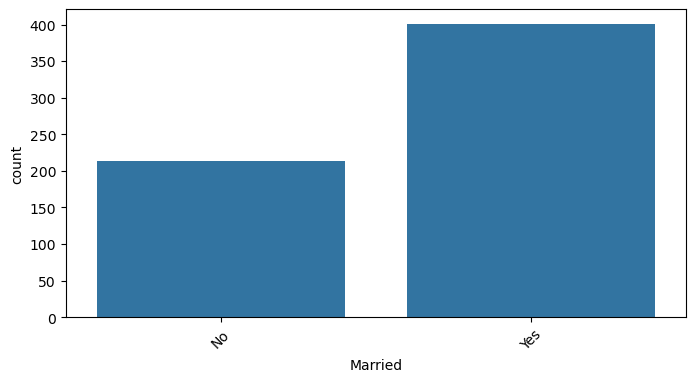

In [24]:
for col in cat_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(data=df, x=col)
    plt.xticks(rotation=45)
    plt.show()

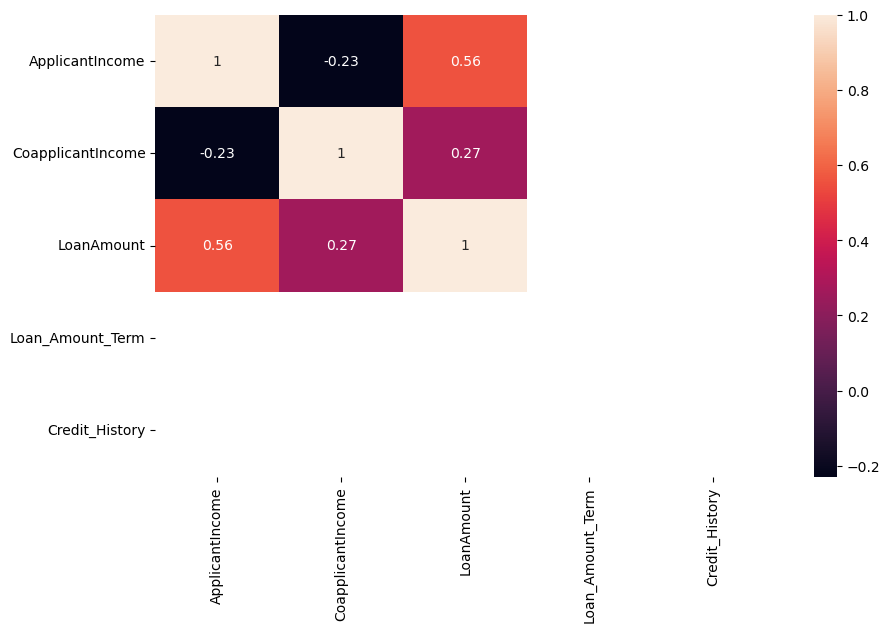

In [25]:
#Correlation
plt.figure(figsize=(10,6))

sns.heatmap(
    df[num_cols].corr(),
    annot=True
)

plt.show()


In [26]:
#There is considerable correlation between income & loan amount

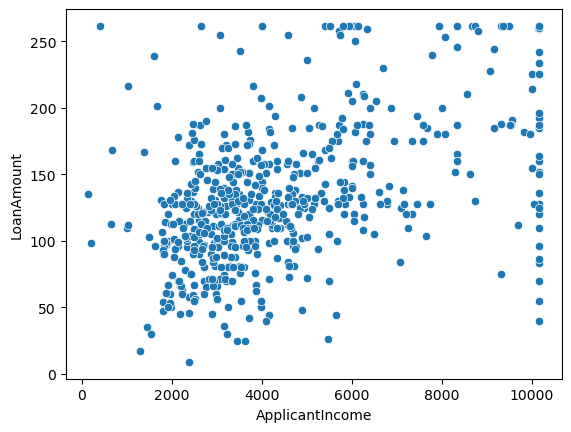

In [27]:
#Relationship analysis
sns.scatterplot(
    data=df,
    x='ApplicantIncome',
    y='LoanAmount'
)

plt.show()

In [28]:
#we can clearly see it 

**Group by analysis**

In [29]:
#1.Average Applicant Income by Gender
print(df.groupby('Gender')['ApplicantIncome'].mean())
#2. Average Loan Amount by Education
print(df.groupby('Education')['LoanAmount'].mean())
#3. Total Applicant Income by Property Area
print(df.groupby('Property_Area')['ApplicantIncome'].sum())
#4. Average Loan Amount by Property Area
print(df.groupby('Property_Area')['LoanAmount'].mean())

Gender
Female    4275.921875
Male      4693.233566
Name: ApplicantIncome, dtype: float64
Education
Graduate        142.554167
Not Graduate    118.779851
Name: LoanAmount, dtype: float64
Property_Area
Rural         849840.75
Semiurban    1063341.50
Urban         921724.25
Name: ApplicantIncome, dtype: float64
Property_Area
Rural        142.659218
Semiurban    137.903433
Urban        132.054455
Name: LoanAmount, dtype: float64


In [30]:
#from this we conclude that male candidates are earning more than female candidates in this data
#More loan is taken by Graduates than non graduates
#People staying in Semiurban area earning more but people staying in Rural area taking more loans as earning less

In [31]:
#Loan Approval Count by Education
print(df.groupby('Education')['Loan_Status'].value_counts())
# Average Income by Loan Status
print(df.groupby('Loan_Status')['ApplicantIncome'].mean())

Education     Loan_Status
Graduate      Y              340
              N              140
Not Graduate  Y               82
              N               52
Name: count, dtype: int64
Loan_Status
N    4618.735677
Y    4616.372630
Name: ApplicantIncome, dtype: float64


Graduates: 340 loans were approved and 140 were rejected.
Not Graduates: 82 loans were approved and 52 were rejected.
So, graduates have a higher loan approval count than non-graduates.
However, the number of applicants in each group is different, so counts alone don't tell us the approval rate.

For the second analysis:

Average income of applicants whose loan was rejected (N) = 4618.74
Average income of applicants whose loan was approved (Y) = 4616.37
The difference is only about 2.36, which is extremely small.
Overall conclusion

Education appears to have some association with loan approval, with graduates having more approvals.
However, Applicant Income does not appear to have a meaningful difference between approved and rejected loans in this dataset. 
Therefore, income alone does not seem to strongly influence loan approval.

In [32]:
#Average Income by Education and Property Area
df.groupby(['Education', 'Property_Area'])['ApplicantIncome'].mean()

Education     Property_Area
Graduate      Rural            5060.853053
              Semiurban        4830.135027
              Urban            4800.179012
Not Graduate  Rural            3893.104167
              Semiurban        3480.570652
              Urban            3602.381250
Name: ApplicantIncome, dtype: float64

In [33]:
#Applicant Income Analysis by Education
df.groupby('Education')['ApplicantIncome'].agg(
    ['mean', 'min', 'max', 'sum']
)

,mean,min,max,sum
Education,,,,
Graduate,4882.991667,150.0,10171.25,2343836.0
Not Graduate,3664.705224,210.0,10171.25,491070.5


graduates have higher average income than non-graduates across all property areas. I also found that rural applicants have the highest average income in both education groups. This analysis helped me understand how applicant income varies across different educational and geographical categories."

**Export cleaned data file for Dashboard**

In [35]:
df.to_csv(r"C:\Users\FCT\Desktop\Loan-Approval-Data-Analysis\cleaned_data.csv",index=False)